In [2]:
from typing import TypedDict

from langgraph.graph import state


class PortfolioState(TypedDict):
    amount_usd:float
    total_usd:float
    total_inr:float





In [3]:

myobj: PortfolioState = {
    'amount_usd': 100,
    'total_usd': 100,
    'total_inr': 34,
}

In [5]:
def calc_total(state: PortfolioState) -> PortfolioState:
    state['total_usd'] = state['amount_usd'] * 1.08
    return state

In [6]:
def covert_to_inr(state: PortfolioState) -> PortfolioState:
    state['total_inr'] = state['total_usd'] * 85
    return state

In [9]:

from langgraph.graph import StateGraph,START,END
builder = StateGraph(PortfolioState)
builder.add_node("calc_total_node",calc_total)
builder.add_node("covert_to_inr_node",covert_to_inr)

builder.add_edge(START,"calc_total_node")
builder.add_edge('calc_total_node', 'covert_to_inr_node')
builder.add_edge('covert_to_inr_node',END)

graph = builder.compile()

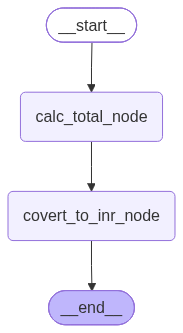

In [10]:
from IPython.display import Image,display

display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
graph.invoke({"amount_usd":100})

{'amount_usd': 100, 'total_usd': 108.0, 'total_inr': 9180.0}